# Sphere, 7 wavelengths: backscattering and shadow

Compare Sionna RT with the analytical solution for a smooth PEC sphere, for both HH and VV. The two icosphere meshes are generated in the notebook. Receiver angle is 0° toward the source and 180° in the forward direction.

Run with the TensorFlow fork of Sionna RT and its diffraction tables. The meshes and analytical reference do not need any external XML, PLY or pickle files. The fork loads GFI and EV tables from its configured paths.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c
from scipy.spatial import ConvexHull

# Let Dr.Jit find LLVM in the active Conda environment on macOS.
if sys.platform == "darwin":
    llvm = Path(sys.prefix) / "lib" / "libLLVM.dylib"
    if llvm.is_file():
        os.environ.setdefault("DRJIT_LIBLLVM_PATH", str(llvm))

import tensorflow as tf
from sionna.rt import PlanarArray, Receiver, Transmitter, load_scene
from sionna.rt.analytical_equations import sphere_tm_fast
from sionna.rt.objects_geometry import ObjectsGeometry

tf.random.set_seed(1)

In [ ]:
dtype = tf.complex64
fc = 2e9
lamda = c / fc
k = 2 * np.pi / lamda
sphere_radius = 7 * lamda
circle_radius = 35 * lamda
tx_dist = 200.0
source_point = np.array([tx_dist, 0.0, 0.0])
field_scale = 4 * np.pi * tx_dist / lamda

rl_method = "env_driven"  # or "exhaustive"
fine_freq = 8  # 8: 642 vertices, 1280 faces
coarse_freq = 2  # 2: 42 vertices, 80 faces
mesh_tilt_deg = (5.0, 5.0)  # about X, then Y
angle_step_deg = 0.5
back_limit_deg = 110.0
shadow_margin_deg = 5.0

In [90]:
def make_icosphere(frequency, radius, tilt_deg=(0.0, 0.0)):
    """Split each icosahedron edge into frequency parts and project to a sphere."""
    golden = (1 + np.sqrt(5)) / 2
    seed = np.array([
        xyz
        for a in (-1, 1)
        for b in (-golden, golden)
        for xyz in [(0, a, b), (b, 0, a), (a, b, 0)]
    ], dtype=float)

    # Divide each base triangle using barycentric coordinates.
    weights = np.array([
        [i, j, frequency - i - j]
        for i in range(frequency + 1)
        for j in range(frequency + 1 - i)
    ]) / frequency
    points = (weights @ seed[ConvexHull(seed).simplices]).reshape(-1, 3)
    vertices = np.unique(np.round(points, 12), axis=0)
    vertices *= radius / np.linalg.norm(vertices, axis=1, keepdims=True)

    ax, ay = np.deg2rad(tilt_deg)
    cx, sx, cy, sy = np.cos(ax), np.sin(ax), np.cos(ay), np.sin(ay)
    rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    vertices = vertices @ (ry @ rx).T

    faces = ConvexHull(vertices).simplices.copy()
    a, b, c = vertices[faces].transpose(1, 0, 2)
    inward = np.einsum("ij,ij->i", a, np.cross(b - a, c - a)) < 0
    faces[inward] = faces[inward][:, [0, 2, 1]]
    return vertices, faces


def write_ply(path, vertices, faces):
    with path.open("w", encoding="ascii") as file:
        file.write(
            f"ply\nformat ascii 1.0\nelement vertex {len(vertices)}\n"
            "property float x\nproperty float y\nproperty float z\n"
            f"element face {len(faces)}\n"
            "property list uchar int vertex_indices\nend_header\n"
        )
        np.savetxt(file, vertices, fmt="%.12g")
        np.savetxt(file, np.column_stack((np.full(len(faces), 3), faces)), fmt="%d")

In [91]:
def setup_scene(frequency, theta_arr_deg, *, double_diffraction=False):
    vertices, faces = make_icosphere(frequency, sphere_radius, mesh_tilt_deg)
    with TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        write_ply(tmp / "sphere.ply", vertices, faces)
        xml = tmp / "sphere.xml"
        xml.write_text("""<scene version="3.0.0">
    <bsdf type="diffuse" id="mat-itu_metal"/>
    <shape type="ply" id="mesh-sphere">
        <string name="filename" value="sphere.ply"/>
        <boolean name="face_normals" value="true"/>
        <ref id="mat-itu_metal"/>
    </shape>
</scene>
""", encoding="utf-8")
        scene = load_scene(str(xml), dtype=dtype)

    scene.frequency = fc
    scene.synthetic_array = True
    scene.tx_array = PlanarArray(
        num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5,
        pattern="iso", polarization="VH", dtype=dtype,
    )
    scene.rx_array = scene.tx_array
    scene.add(Transmitter(name="tx", position=source_point, dtype=dtype))
    theta_arr = np.deg2rad(theta_arr_deg)
    receive_points = circle_radius * np.column_stack(
        (np.cos(theta_arr), np.sin(theta_arr), np.zeros_like(theta_arr))
    )
    for i, point in enumerate(receive_points):
        scene.add(Receiver(name=f"rx_{i}", position=point, dtype=dtype))

    solver = scene._solver_paths
    obj_geom = ObjectsGeometry(solver, is_table_gfi=True)
    obj_geom.is_vertex_diffraction = True
    obj_geom.is_double_diffraction = double_diffraction
    obj_geom.init_objects(list(scene.objects), [None])
    solver.vertex_diffraction.set_objects_geometry(obj_geom)
    solver.double_diffraction.set_objects_geometry(obj_geom)
    print(f"Sphere mesh: {len(vertices)} vertices, {len(faces)} faces")
    return scene, obj_geom

In [92]:
def field_db(magnitude):
    return 20 * np.log10(np.maximum(magnitude, 1e-30))


def sphere_reference_db(theta_arr_deg, *, total):
    theta = np.deg2rad(np.abs(np.mod(theta_arr_deg, 360.0) - 180.0))
    theta = np.clip(theta, 1e-6, np.pi - 1e-6)

    reference = {}
    for pol, phi in (("HH", 0.0), ("VV", np.pi / 2)):
        total_field, scattered_field = sphere_tm_fast(
            np.full_like(theta, phi), theta, sphere_radius, circle_radius, k
        )
        reference[pol] = field_db(total_field if total else scattered_field)
    return reference


def run(scene, *, los=False, ee=False, ev=False, sv=False):
    dd = scene._solver_paths.double_diffraction
    dd.is_only_in_nlos = False
    dd.is_only_close_2_transition = True
    dd.close_2_transition_eps = 0.5
    dd.is_only_coplanar = dd.is_ww_analytical = True
    dd.is_add_slope = dd.is_vw_reversed_compute_fields = True
    dd.is_wedge_wedge = ee
    dd.is_wedge_vertex = dd.is_vertex_wedge = ev
    dd.is_wedge_wedge_sv = sv
    dd.sv_add_delta = True
    dd.is_vertex_vertex = dd.is_eee = False

    paths = scene.compute_paths(
        max_depth=1, method=rl_method, num_samples=10**6,
        los=los, reflection=True, diffraction=True, edge_diffraction=False,
        vertex_diffraction=True, double_diffraction=ee or ev or sv,
    )
    paths.normalize_delays = False
    a, _ = paths.cir()
    a = np.asarray(a)
    assert a.shape[2] == a.shape[4] == 2

    results = {}
    for pol, ant in (("HH", 1), ("VV", 0)):
        amplitudes = a[0, :, ant, 0, ant, :, 0]
        amplitudes = np.where(np.isfinite(amplitudes), amplitudes, 0j)
        results[pol] = field_db(field_scale * np.abs(amplitudes.sum(axis=1)))
    return results, paths

## Backscattering · fine mesh

Scattered field from reflection, wedge diffraction and vertex diffraction. LOS is disabled.

In [93]:
back_deg = np.arange(-back_limit_deg, back_limit_deg + 1e-9, angle_step_deg)
back_scene, back_geom = setup_scene(fine_freq, back_deg)
back_rt, back_paths = run(back_scene)
back_reference = sphere_reference_db(back_deg, total=False)

num_edges: tf.Tensor(0, shape=(), dtype=int32)
num_wedges: 1920
Removed 0 duplicate vertex-wedge contributions.
num vertices: 642
Sphere mesh: 642 vertices, 1280 faces


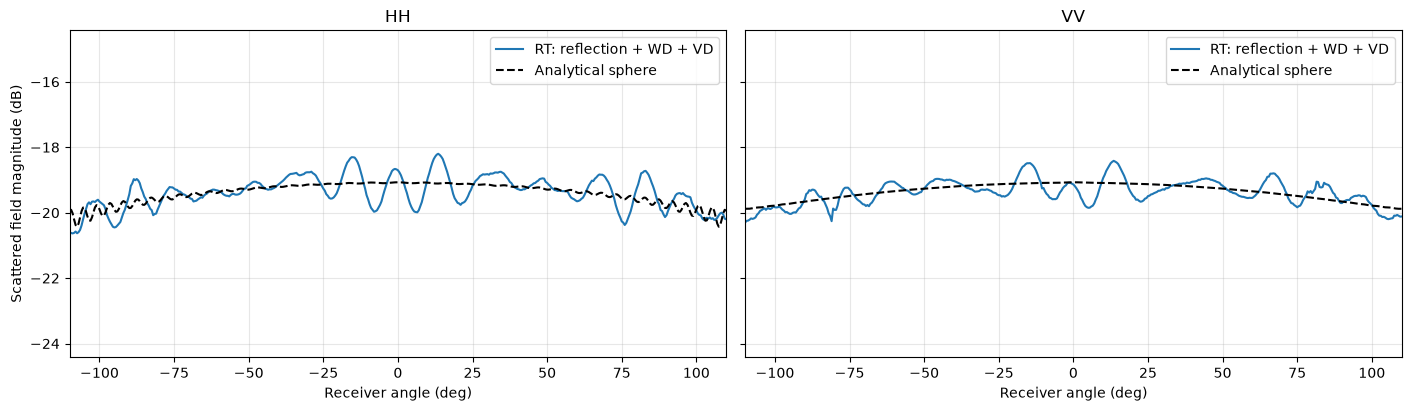

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, constrained_layout=True)

for ax, pol in zip(axes, ("HH", "VV")):
    ax.plot(back_deg, back_rt[pol], label="RT: reflection + WD + VD")
    ax.plot(back_deg, back_reference[pol], "k--", label="Analytical sphere")
    ax.set(title=pol, xlabel="Receiver angle (deg)", xlim=(back_deg[0], back_deg[-1]))
    ax.grid(alpha=0.3)
    ax.legend()

y_min, y_max = axes[0].get_ylim()
if y_max - y_min < 10.0:
    y_mid = (y_min + y_max) / 2
    axes[0].set_ylim(y_mid - 5.0, y_mid + 5.0)

axes[0].set_ylabel("Scattered field magnitude (dB)")
plt.show()

## Shadow · coarse mesh

The total field includes LOS wherever the mesh leaves it visible. The dashed vertical markers are the LOS transitions of the coarse mesh. Compare first order, first order plus EE, and then all second-order terms used here (EE, EV/VE and SV).

In [95]:
shadow_deg = np.arange(155.0, 205.0 + 1e-9, angle_step_deg)
shadow_scene, shadow_geom = setup_scene(coarse_freq, shadow_deg, double_diffraction=True)

direct = shadow_scene.compute_paths(
    max_depth=1, method="exhaustive", los=True,
    reflection=False, diffraction=False, vertex_diffraction=False, double_diffraction=False,
)
shadow = ~np.any(np.asarray(direct.mask)[0, :, 0, :], axis=-1)
boundary = np.flatnonzero(shadow[:-1] != shadow[1:])
sb_deg = 0.5 * (shadow_deg[boundary] + shadow_deg[boundary + 1])
if not len(sb_deg):
    raise ValueError("No LOS transitions found. Widen the receiver sweep.")
xlim = (sb_deg.min() - shadow_margin_deg, sb_deg.max() + shadow_margin_deg)

num_edges: tf.Tensor(0, shape=(), dtype=int32)
num_wedges: 120
Removed 0 duplicate vertex-wedge contributions.
num vertices: 42
Sphere mesh: 42 vertices, 80 faces


In [96]:
curves = {}
curves["RT: first order"], shadow_first_paths = run(shadow_scene, los=True)
curves["RT + EE"], shadow_ee_paths = run(shadow_scene, los=True, ee=True)
curves["RT + EE + EV/VE + SV"], shadow_paths = run(shadow_scene, los=True, ee=True, ev=True, sv=True)
shadow_reference = sphere_reference_db(shadow_deg, total=True)

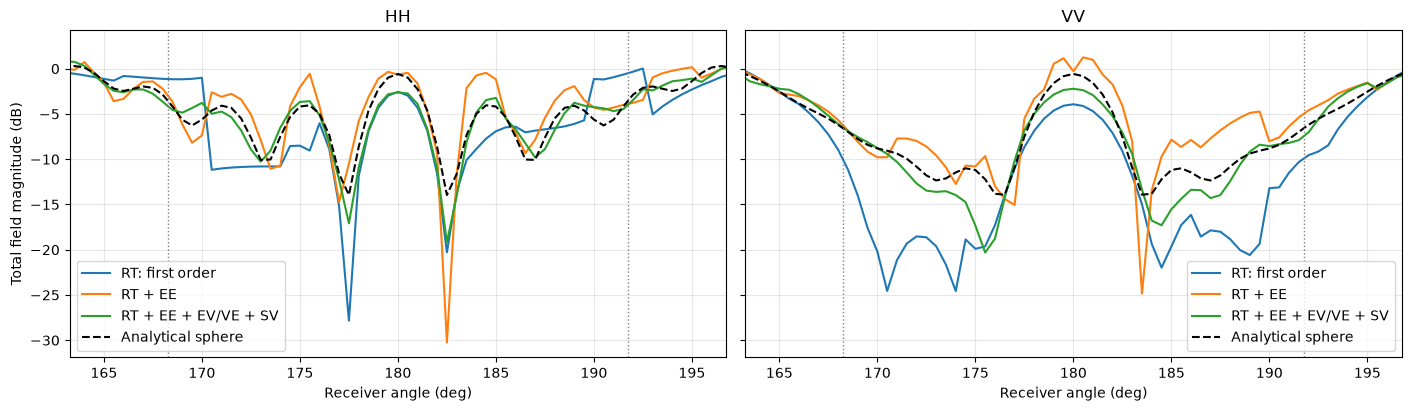

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, constrained_layout=True)
for ax, pol in zip(axes, ("HH", "VV")):
    for label, result in curves.items():
        ax.plot(shadow_deg, result[pol], label=label)
    ax.plot(shadow_deg, shadow_reference[pol], "k--", label="Analytical sphere")
    for angle in sb_deg:
        ax.axvline(angle, color="gray", ls=":", lw=1)
    ax.set(title=pol, xlabel="Receiver angle (deg)", xlim=xlim)
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Total field magnitude (dB)")
plt.show()